In [159]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from Bio import SeqIO
from Bio.Data import CodonTable
from Bio.SeqUtils import seq3
from Bio.Seq import Seq

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.stats import spearmanr
from adjustText import adjust_text

data_dir = Path("../data")
output_dir = data_dir / "COX1_analysis"

In [39]:
aa_instect_df = pd.read_csv("../data/midori_Blattodea_aa_fracs.tsv", sep='\t')

In [40]:
cytb_insect_df = aa_instect_df[aa_instect_df['Gene_name'] == 'Cytb'].reset_index(drop=True)

In [41]:
cytb_insect_df

,Species_name,Organism,Gene_name,Phe_frac,Leu_frac,Leu2_frac,Ser_frac,Pro_frac,Cys_frac,Trp_frac,...,Ser2_frac,Asp_frac,Glu_frac,Asn_frac,Lys_frac,Val_frac,Ile_frac,Met_frac,Ala_frac,Thr_frac
0,Acanthotermes_acanthothorax_187525,Termites,Cytb,0.044974,0.021164,0.005291,0.097884,0.018519,0.103175,0.066138,...,0.010582,0.068783,0.068783,0.026455,0.015873,0.126984,0.018519,0.013228,0.013228,0.005291
1,Acholotermes_chirotus_1934430,Termites,Cytb,0.039683,0.021164,0.007937,0.116402,0.010582,0.119048,0.066138,...,0.010582,0.055556,0.055556,0.026455,0.023810,0.103175,0.042328,0.018519,0.007937,0.007937
2,Aciculitermes_aciculatus_1934431,Termites,Cytb,0.042328,0.023810,0.005291,0.111111,0.007937,0.097884,0.052910,...,0.044974,0.044974,0.042328,0.039683,0.037037,0.095238,0.031746,0.029101,0.015873,0.010582
3,Aciculitermes_maymyoensis_229658,Termites,Cytb,0.042328,0.018519,0.007937,0.100529,0.021164,0.100529,0.050265,...,0.039683,0.050265,0.058201,0.047619,0.031746,0.074074,0.047619,0.037037,0.010582,0.007937
4,Acidnotermes_praus_1934432,Termites,Cytb,0.024064,0.026738,0.016043,0.085561,0.032086,0.104278,0.069519,...,0.021390,0.037433,0.045455,0.034759,0.040107,0.096257,0.034759,0.029412,0.013369,0.013369
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
392,Tumulitermes_pastinator_286182,Termites,Cytb,0.039683,0.021164,0.007937,0.100529,0.015873,0.116402,0.060847,...,0.021164,0.066138,0.068783,0.026455,0.021164,0.121693,0.026455,0.013228,0.021164,0.002646
393,Tumulitermes_recalvus_1934613,Termites,Cytb,0.039683,0.023810,0.005291,0.108466,0.007937,0.119048,0.055556,...,0.026455,0.037037,0.066138,0.037037,0.029101,0.108466,0.029101,0.021164,0.007937,0.015873
394,Verrucositermes_tuberosus_378004,Termites,Cytb,0.044974,0.023810,0.002646,0.100529,0.013228,0.113757,0.060847,...,0.029101,0.060847,0.060847,0.034392,0.018519,0.108466,0.031746,0.015873,0.021164,0.007937
395,Zootermopsis_angusticollis_7503,Termites,Cytb,0.050265,0.023810,0.002646,0.116402,0.007937,0.084656,0.082011,...,0.023810,0.068783,0.058201,0.034392,0.021164,0.103175,0.039683,0.018519,0.007937,0.007937


In [42]:
# Select amino acid frequencies
aa_cols = [
    col for col in cytb_insect_df.columns
    if col.endswith("_frac")
]

# Prepare PCA matrix
X = cytb_insect_df[aa_cols].copy()

# Standardize variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA
pca = PCA(n_components=2)
scores = pca.fit_transform(X_scaled)

# PCA scores
pca_df = cytb_insect_df[
    ["Species_name", "Organism"]
].copy()

pca_df["PC1"] = scores[:, 0]
pca_df["PC2"] = scores[:, 1]

# PCA loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=aa_cols,
    columns=["PC1", "PC2"]
)

# Explained variance
explained_variance = pca.explained_variance_ratio_ * 100

print("Explained variance:")
print(f"PC1: {explained_variance[0]:.2f}%")
print(f"PC2: {explained_variance[1]:.2f}%")

Explained variance:
PC1: 41.82%
PC2: 16.43%


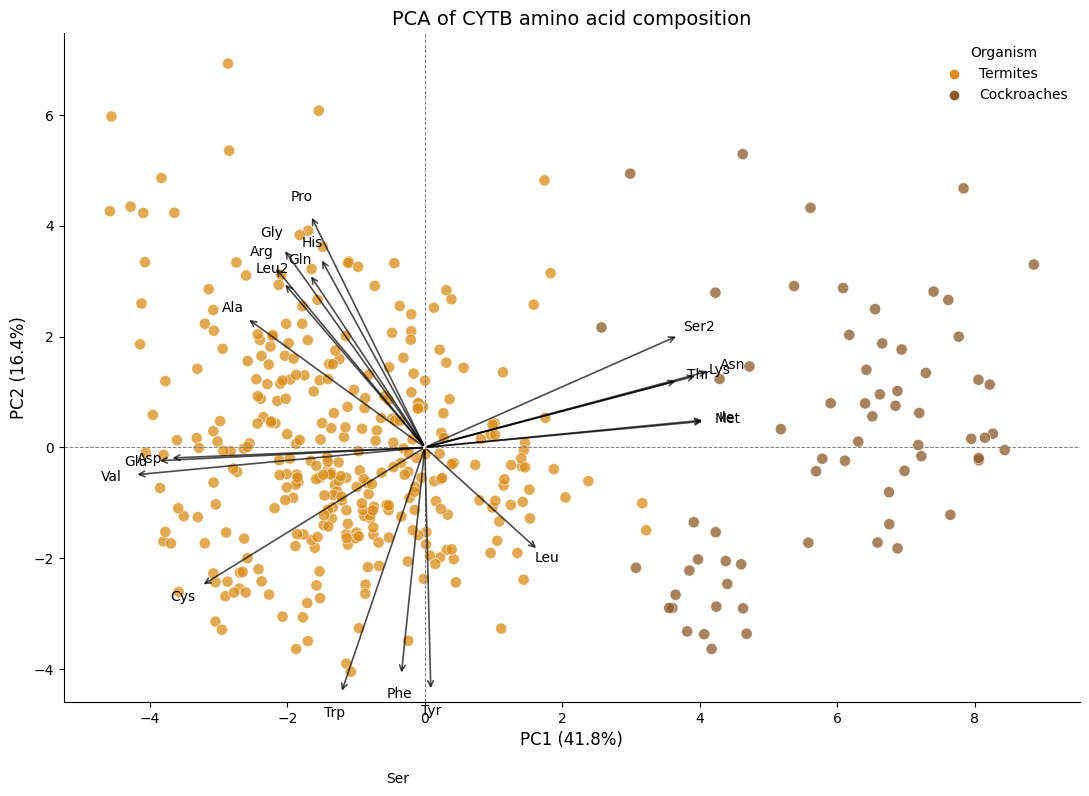

In [43]:
fig, ax = plt.subplots(figsize=(11, 8))

palette = {
    "Termites": "#D98C1A",
    "Cockroaches": "#8B5A2B"
}

# Species
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Organism",
    palette=palette,
    s=65,
    alpha=0.75,
    edgecolor="white",
    linewidth=0.5,
    ax=ax
)

# Scale arrows to PCA scores
scale = 0.8 * min(
    np.max(np.abs(scores[:, 0])) / np.max(np.abs(loadings["PC1"])),
    np.max(np.abs(scores[:, 1])) / np.max(np.abs(loadings["PC2"]))
)

# Amino acid vectors
for aa in aa_cols:

    x = loadings.loc[aa, "PC1"] * scale
    y = loadings.loc[aa, "PC2"] * scale

    ax.annotate(
        "",
        xy=(x, y),
        xytext=(0, 0),
        arrowprops=dict(
            arrowstyle="->",
            color="black",
            lw=1.2,
            alpha=0.7
        )
    )

    ax.text(
        x * 1.08,
        y * 1.08,
        aa.replace("_frac", ""),
        fontsize=10,
        ha="center",
        va="center"
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=0.7)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.7)

ax.set_xlabel(f"PC1 ({explained_variance[0]:.1f}%)", fontsize=12)
ax.set_ylabel(f"PC2 ({explained_variance[1]:.1f}%)", fontsize=12)

ax.set_title(
    "PCA of CYTB amino acid composition",
    fontsize=14
)

ax.legend(title="Organism", frameon=False)

sns.despine()
plt.tight_layout()
plt.show()

In [131]:
# Invertebrate mitochondrial codon table
MITO_TABLE = 5

codon_table = CodonTable.unambiguous_dna_by_id[MITO_TABLE]

# Standard amino acids
amino_acids = list("ACDEFGHIKLMNPQRSTVWY")

# Replace Leu and Ser with separate codon families
aa_features = [
    aa for aa in amino_acids
    if aa not in ["L", "S"]
]

aa_features += [
    "Leu_TT",
    "Leu_CT",
    "Ser_TC",
    "Ser_AG"
]


def calculate_aa_frequencies(sequence):

    sequence = str(sequence).upper().replace("U", "T")

    counts = dict.fromkeys(aa_features, 0)

    valid_codons = 0
    stop_codons = 0
    ambiguous_codons = 0

    for i in range(0, len(sequence) - 2, 3):

        codon = sequence[i:i+3]

        if any(base not in "ACGT" for base in codon):
            ambiguous_codons += 1
            continue

        if codon in codon_table.stop_codons:
            stop_codons += 1
            continue

        aa = codon_table.forward_table.get(codon)

        if aa is None:
            ambiguous_codons += 1
            continue

        # Leucine
        if aa == "L":

            if codon.startswith("TT"):
                counts["Leu_TT"] += 1

            elif codon.startswith("CT"):
                counts["Leu_CT"] += 1

        # Serine
        elif aa == "S":

            if codon.startswith("TC"):
                counts["Ser_TC"] += 1

            elif codon.startswith("AG"):
                counts["Ser_AG"] += 1

        # Other amino acids
        else:
            counts[aa] += 1

        valid_codons += 1

    frequencies = {
        f"{aa}_frac": (
            counts[aa] / valid_codons
            if valid_codons > 0 else np.nan
        )
        for aa in aa_features
    }

    return {
        **frequencies,
        "Valid_codons": valid_codons,
        "Stop_codons": stop_codons,
        "Ambiguous_codons": ambiguous_codons
    }

In [133]:
def find_best_frame(sequence):

    sequence = str(sequence).upper().replace("U", "T")

    candidates = []

    for strand, seq in [
        ("+", sequence),
        ("-", str(Seq(sequence).reverse_complement()))
    ]:

        for frame in range(3):

            coding_seq = seq[frame:]

            coding_seq = coding_seq[
                :len(coding_seq) // 3 * 3
            ]

            result = calculate_aa_frequencies(coding_seq)

            candidates.append({
                "strand": strand,
                "frame": frame,
                "sequence": coding_seq,
                "stops": result["Stop_codons"],
                "valid": result["Valid_codons"],
                "ambiguous": result["Ambiguous_codons"]
            })

    candidates.sort(
        key=lambda x: (
            x["stops"],
            x["ambiguous"],
            -x["valid"]
        )
    )

    return candidates[0]

In [147]:
records = []

for record in SeqIO.parse("../data/all_insects_CO1seqs.fa", "fasta"):

    accession = record.id

    match = re.search(
        r"\[([^\]]+)\]",
        record.description
    )

    if match is None:
        continue

    species_id = match.group(1)

    scientific_name = re.sub(
        r"_\d+$", "", species_id
    ).replace("_", " ")

    # Find coding frame
    best = find_best_frame(record.seq)

    # Calculate amino acid composition
    aa_data = calculate_aa_frequencies(
        best["sequence"]
    )

    records.append({
        "Accession": accession,
        "Species_name": species_id,
        "Scientific_name": scientific_name,
        "Length_nt": len(record.seq),
        "Strand": best["strand"],
        "Frame": best["frame"],
        **aa_data
    })

cox1_df = pd.DataFrame(records)

print("Total sequences:", len(cox1_df))

display(cox1_df.head())

Total sequences: 15812


,Accession,Species_name,Scientific_name,Length_nt,Strand,Frame,A_frac,C_frac,D_frac,E_frac,...,V_frac,W_frac,Y_frac,Leu_TT_frac,Leu_CT_frac,Ser_TC_frac,Ser_AG_frac,Valid_codons,Stop_codons,Ambiguous_codons
0,MF040925.1,Heterolepisma_sclerophylla_2171747,Heterolepisma sclerophylla,646,+,1,0.079070,0.0,0.027907,0.018605,...,0.055814,0.023256,0.018605,0.046512,0.102326,0.055814,0.018605,215,0,0
1,MT108230.1,Lepisma_saccharina_50586,Lepisma saccharina,1537,+,0,0.072266,0.0,0.029297,0.019531,...,0.070312,0.029297,0.031250,0.033203,0.085938,0.052734,0.027344,512,0,0
2,MW129798.1,Trichatelura_manni_2873228,Trichatelura manni,674,+,1,0.098214,0.0,0.040179,0.004464,...,0.058036,0.026786,0.017857,0.017857,0.129464,0.053571,0.017857,224,0,0
3,JX412826.1,Brachinus_crepitans_877828,Brachinus crepitans,1545,+,0,0.066148,0.0,0.027237,0.019455,...,0.060311,0.027237,0.035019,0.083658,0.035019,0.064202,0.025292,514,1,0
4,HM433227.1,Brachinus_elongatulus_1977114,Brachinus elongatulus,658,+,1,0.082192,0.0,0.031963,0.013699,...,0.068493,0.022831,0.018265,0.100457,0.050228,0.050228,0.031963,219,0,0


In [148]:
print(
    cox1_df["Stop_codons"].value_counts().head(10)
)

print(
    cox1_df["Valid_codons"].describe()
)

0    14347
1     1464
2        1
Name: Stop_codons, dtype: int64
count    15812.000000
mean       298.424741
std        117.041129
min         71.000000
25%        219.000000
50%        222.000000
75%        399.000000
max        549.000000
Name: Valid_codons, dtype: float64


In [149]:
cox1_df["Ambiguous_fraction"] = (
    cox1_df["Ambiguous_codons"] /
    (
        cox1_df["Valid_codons"]
        + cox1_df["Ambiguous_codons"]
        + cox1_df["Stop_codons"]
    ).replace(0, np.nan)
)

cox1_df = cox1_df[
    (cox1_df["Stop_codons"] == 0)
    & (cox1_df["Valid_codons"] >= 150)
    & (cox1_df["Ambiguous_fraction"] <= 0.05)
].copy()

print("Sequences after QC:", len(cox1_df))

Sequences after QC: 14113


In [150]:
cox1_df.to_csv(
    output_dir / "COX1_amino_acid_frequencies.csv",
    index=False
)

In [151]:
taxonomy_cols = [
    "Species",
    "Genus",
    "Family",
    "Order",
    "Class",
    "Phylum",
    "Kingdom"
]

taxonomy_df = pd.read_csv(
    "../data/all_insects_CO1.tax",
    sep=";",
    header=None,
    names=taxonomy_cols
)

taxonomy_df["Scientific_name"] = (
    taxonomy_df["Species"]
    .str.replace("_", " ", regex=False)
    .str.strip()
)

taxonomy_df = taxonomy_df[
    taxonomy_df["Class"] == "Insecta"
].copy()

taxonomy_df = taxonomy_df[
    ["Scientific_name", "Family", "Order"]
].drop_duplicates()

# Check conflicting taxonomic assignments
conflicts = (
    taxonomy_df.groupby("Scientific_name")["Family"]
    .nunique()
)

assert not (conflicts > 1).any(), (
    "Conflicting family assignments in taxonomy file"
)

taxonomy_df = taxonomy_df.drop_duplicates(
    subset="Scientific_name"
)

# Merge with amino acid composition
cox1_df = cox1_df.merge(
    taxonomy_df,
    on="Scientific_name",
    how="left",
    validate="many_to_one"
)

print(
    "Sequences with family:",
    cox1_df["Family"].notna().sum()
)

display(cox1_df.head())

Sequences with family: 14105


,Accession,Species_name,Scientific_name,Length_nt,Strand,Frame,A_frac,C_frac,D_frac,E_frac,...,Leu_TT_frac,Leu_CT_frac,Ser_TC_frac,Ser_AG_frac,Valid_codons,Stop_codons,Ambiguous_codons,Ambiguous_fraction,Family,Order
0,MF040925.1,Heterolepisma_sclerophylla_2171747,Heterolepisma sclerophylla,646,+,1,0.079070,0.0,0.027907,0.018605,...,0.046512,0.102326,0.055814,0.018605,215,0,0,0.0,Lepismatidae,Zygentoma
1,MT108230.1,Lepisma_saccharina_50586,Lepisma saccharina,1537,+,0,0.072266,0.0,0.029297,0.019531,...,0.033203,0.085938,0.052734,0.027344,512,0,0,0.0,Lepismatidae,Zygentoma
2,MW129798.1,Trichatelura_manni_2873228,Trichatelura manni,674,+,1,0.098214,0.0,0.040179,0.004464,...,0.017857,0.129464,0.053571,0.017857,224,0,0,0.0,Nicoletiidae,Zygentoma
3,HM433227.1,Brachinus_elongatulus_1977114,Brachinus elongatulus,658,+,1,0.082192,0.0,0.031963,0.013699,...,0.100457,0.050228,0.050228,0.031963,219,0,0,0.0,Carabidae,Coleoptera
4,KU909800.1,Brachinus_explodens_1587108,Brachinus explodens,658,+,1,0.077626,0.0,0.031963,0.013699,...,0.109589,0.041096,0.050228,0.036530,219,0,0,0.0,Carabidae,Coleoptera


In [153]:
longevity_df = pd.read_csv(
    "../data/Dataset_longevity.csv",
    encoding="cp1252"
)

# Convert longevity to numeric
for col in ["M_longevity", "F_longevity"]:

    longevity_df[col] = pd.to_numeric(
        longevity_df[col],
        errors="coerce"
    )

# Only observations with both sexes
longevity_df = longevity_df.dropna(
    subset=["M_longevity", "F_longevity"]
).copy()

# Positive longevity
longevity_df = longevity_df[
    (longevity_df["M_longevity"] > 0)
    & (longevity_df["F_longevity"] > 0)
].copy()

# Keep comparable measurement types for primary analysis
longevity_df = longevity_df[
    longevity_df["longevity_measure"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("mean")
].copy()

# Combined adult longevity
longevity_df["Mean_longevity"] = (
    longevity_df["M_longevity"] +
    longevity_df["F_longevity"]
) / 2

# Normalize family names
longevity_df["Family_key"] = (
    longevity_df["family"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

longevity_df["Species_key"] = (
    longevity_df["genus"].astype("string").str.strip()
    + " "
    + longevity_df["species"].astype("string").str.strip()
).str.casefold()

# One record per species
longevity_species = (
    longevity_df
    .groupby(["Family_key", "Species_key"], as_index=False)
    .agg(
        Mean_longevity=("Mean_longevity", "mean")
    )
)

# Family-level longevity
family_longevity = (
    longevity_species
    .groupby("Family_key", as_index=False)
    .agg(
        Mean_longevity=("Mean_longevity", "mean"),
        Median_longevity=("Mean_longevity", "median"),
        N_longevity_species=("Species_key", "nunique")
    )
)

display(family_longevity.head())

,Family_key,Mean_longevity,Median_longevity,N_longevity_species
0,acrididae,89.782143,71.775,14
1,agromyzidae,9.800000,9.800,2
2,aleyrodidae,13.300000,13.300,1
3,alydidae,38.450000,38.450,2
4,anisolabididae,101.525000,101.525,2


In [154]:
cox1_df["Family_key"] = (
    cox1_df["Family"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

merged = cox1_df.merge(
    family_longevity[
        [
            "Family_key",
            "Mean_longevity",
            "N_longevity_species"
        ]
    ],
    on="Family_key",
    how="left",
    validate="many_to_one"
)

# Remove unknown longevity
merged = merged.dropna(
    subset=["Mean_longevity"]
).copy()

print("Sequences:", len(merged))
print("Species:", merged["Scientific_name"].nunique())
print("Families:", merged["Family"].nunique())

merged.to_csv(
    output_dir / "COX1_family_longevity_merged.csv",
    index=False
)

Sequences: 7911
Species: 7911
Families: 104


In [155]:
family_categories = (
    merged[["Family_key", "Mean_longevity"]]
    .drop_duplicates(subset=["Family_key"])
    .copy()
)

family_categories["Longevity_category"] = pd.qcut(
    family_categories["Mean_longevity"],
    q=10,
    duplicates="drop"
)

intervals = (
    family_categories["Longevity_category"]
    .cat.categories
)

category_order = [
    f"{interval.left:.2f}–{interval.right:.2f}"
    for interval in intervals
]

interval_to_label = dict(
    zip(intervals, category_order)
)

family_categories["Longevity_category"] = (
    family_categories["Longevity_category"]
    .map(interval_to_label)
)

merged = merged.merge(
    family_categories[
        ["Family_key", "Longevity_category"]
    ],
    on="Family_key",
    how="left",
    validate="many_to_one"
)

merged["Longevity_category"] = pd.Categorical(
    merged["Longevity_category"],
    categories=category_order,
    ordered=True
)

display(
    merged.groupby(
        "Longevity_category",
        observed=True
    ).agg(
        N_species=("Scientific_name", "nunique"),
        N_families=("Family_key", "nunique"),
        Min_longevity=("Mean_longevity", "min"),
        Max_longevity=("Mean_longevity", "max")
    )
)

,N_species,N_families,Min_longevity,Max_longevity
Longevity_category,,,,
1.80–8.60,374,12,1.800000,8.600000
8.60–10.94,947,9,8.800000,10.900000
10.94–14.87,1304,10,10.967857,14.700000
14.87–20.61,1171,11,14.887500,20.475000
20.61–25.04,1330,10,21.150000,24.925000
25.04–34.62,799,10,25.150000,33.700000
34.62–44.08,218,11,34.850000,43.800000
44.08–57.03,610,10,46.550000,56.500000
57.03–85.35,526,10,57.821739,83.002941


In [156]:
aa_cols = [
    f"{aa}_frac"
    for aa in aa_features
]

# One amino acid profile per species
pca_data = (
    merged
    .groupby(
        [
            "Scientific_name",
            "Family",
            "Family_key",
            "Mean_longevity",
            "Longevity_category"
        ],
        observed=True,
        as_index=False
    )[aa_cols]
    .mean()
)

pca_data = pca_data.dropna(
    subset=aa_cols
).copy()

print("PCA observations:", len(pca_data))
print("PCA features:", len(aa_cols))

PCA observations: 7911
PCA features: 22


In [157]:
print(
    pca_data[aa_cols]
    .sum(axis=1)
    .describe()
)

count    7.911000e+03
mean     1.000000e+00
std      1.520479e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64


In [158]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    pca_data[aa_cols]
)

pca = PCA(n_components=2)

scores = pca.fit_transform(X_scaled)

pca_data["PC1"] = scores[:, 0]
pca_data["PC2"] = scores[:, 1]

loadings = pd.DataFrame(
    pca.components_.T,
    index=aa_features,
    columns=["PC1", "PC2"]
)

explained_variance = (
    pca.explained_variance_ratio_ * 100
)

print(f"PC1: {explained_variance[0]:.2f}%")
print(f"PC2: {explained_variance[1]:.2f}%")

PC1: 36.45%
PC2: 17.02%


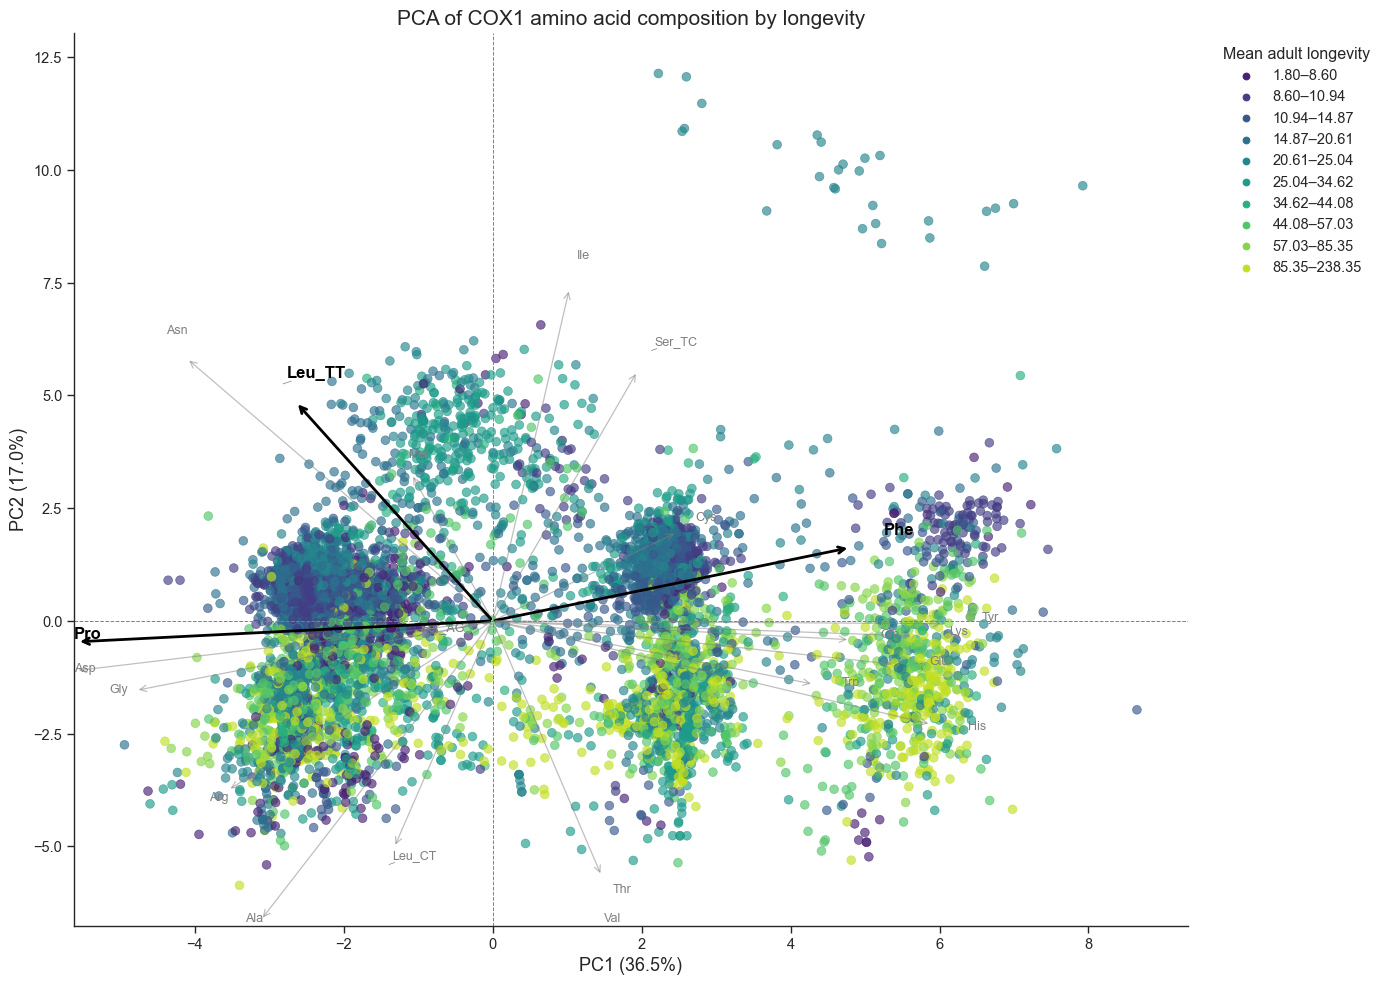

In [160]:
fig, ax = plt.subplots(figsize=(14, 10))

palette = dict(zip(
    category_order,
    sns.color_palette("viridis", len(category_order))
))

sns.scatterplot(
    data=pca_data,
    x="PC1",
    y="PC2",
    hue="Longevity_category",
    hue_order=category_order,
    palette=palette,
    s=40,
    alpha=0.65,
    edgecolor=None,
    rasterized=True,
    ax=ax
)

# Arrow scaling
scale = 0.7 * min(
    np.max(np.abs(scores[:, 0])) /
    np.max(np.abs(loadings["PC1"])),

    np.max(np.abs(scores[:, 1])) /
    np.max(np.abs(loadings["PC2"]))
)

highlight_aas = {"P", "F", "Leu_TT"}

texts = []

for aa in aa_features:

    x = loadings.loc[aa, "PC1"] * scale
    y = loadings.loc[aa, "PC2"] * scale

    highlight = aa in highlight_aas

    color = "black" if highlight else "gray"

    ax.annotate(
        "",
        xy=(x, y),
        xytext=(0, 0),
        arrowprops=dict(
            arrowstyle="->",
            color=color,
            lw=2 if highlight else 0.9,
            alpha=1 if highlight else 0.5
        ),
        zorder=5
    )

    label = (
        aa if aa in
        {"Leu_TT", "Leu_CT", "Ser_TC", "Ser_AG"}
        else seq3(aa)
    )

    txt = ax.text(
        x * 1.08,
        y * 1.08,
        label,
        fontsize=12 if highlight else 9,
        fontweight="bold" if highlight else "normal",
        color=color
    )

    texts.append(txt)

adjust_text(
    texts,
    ax=ax,
    expand=(1.2, 1.3),
    arrowprops=dict(
        arrowstyle="-",
        color="gray",
        lw=0.5
    )
)

ax.axhline(0, color="gray", ls="--", lw=0.7)
ax.axvline(0, color="gray", ls="--", lw=0.7)

ax.set_xlabel(
    f"PC1 ({explained_variance[0]:.1f}%)",
    fontsize=13
)

ax.set_ylabel(
    f"PC2 ({explained_variance[1]:.1f}%)",
    fontsize=13
)

ax.set_title(
    "PCA of COX1 amino acid composition by longevity",
    fontsize=15
)

ax.legend(
    title="Mean adult longevity",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

sns.despine()
plt.tight_layout()

plt.savefig(
    output_dir / "COX1_PCA_longevity.pdf",
    bbox_inches="tight"
)

plt.show()

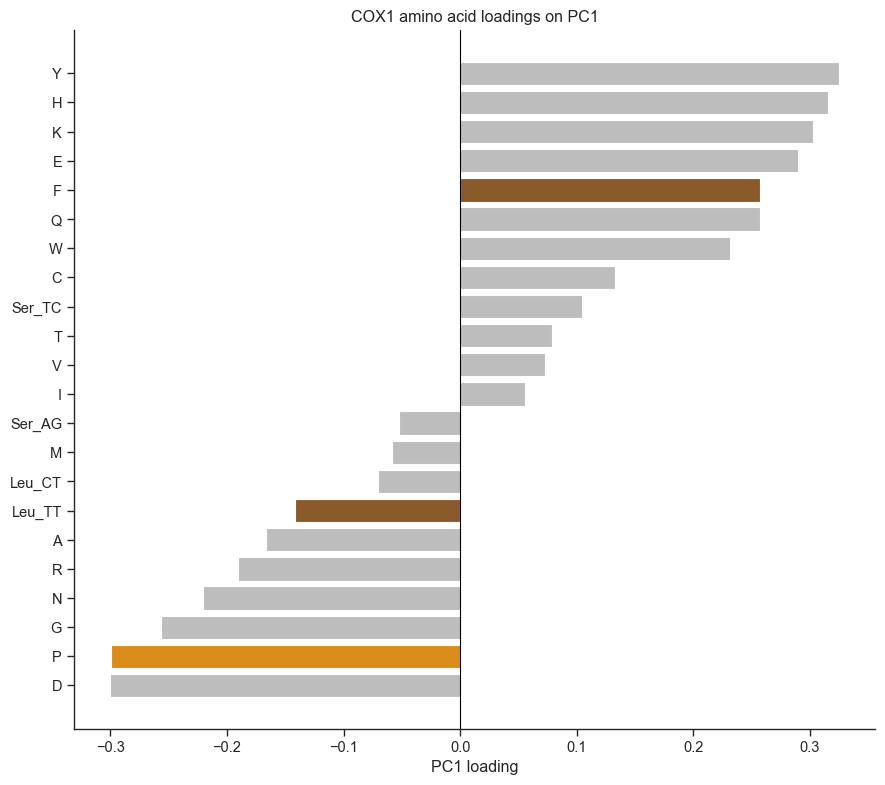

In [161]:
pc1_loadings = loadings["PC1"].sort_values()

colors = []

for aa in pc1_loadings.index:

    if aa == "P":
        colors.append("#D98C1A")

    elif aa in {"F", "Leu_TT"}:
        colors.append("#8B5A2B")

    else:
        colors.append("#BDBDBD")

fig, ax = plt.subplots(figsize=(9, 8))

ax.barh(
    pc1_loadings.index,
    pc1_loadings.values,
    color=colors
)

ax.axvline(0, color="black", lw=0.8)

ax.set_xlabel("PC1 loading")
ax.set_title("COX1 amino acid loadings on PC1")

sns.despine()
plt.tight_layout()

plt.savefig(
    output_dir / "COX1_PC1_loadings.pdf",
    bbox_inches="tight"
)

plt.show()

In [162]:
family_pca = (
    pca_data
    .groupby("Family", as_index=False)
    .agg(
        PC1=("PC1", "mean"),
        PC2=("PC2", "mean"),
        Mean_longevity=("Mean_longevity", "first"),
        N_species=("Scientific_name", "nunique")
    )
)

results = []

for component in ["PC1", "PC2"]:

    rho, p_value = spearmanr(
        family_pca[component],
        family_pca["Mean_longevity"]
    )

    results.append({
        "Component": component,
        "N_families": len(family_pca),
        "Spearman_rho": rho,
        "p_value": p_value
    })

pca_correlation = pd.DataFrame(results)

display(pca_correlation.round(4))

,Component,N_families,Spearman_rho,p_value
0,PC1,104,0.2263,0.0209
1,PC2,104,-0.3447,0.0003


In [170]:
family_pca

,Family,PC1,PC2,Mean_longevity,N_species
0,Acrididae,0.562869,-1.871447,89.782143,76
1,Agromyzidae,0.567570,-1.619967,9.800000,46
2,Aleyrodidae,1.572672,1.335843,13.300000,11
3,Alydidae,0.393428,-0.453801,38.450000,8
4,Anthocoridae,0.668435,-0.831658,43.257000,10
...,...,...,...,...,...
99,Tingidae,-0.194390,-0.203019,55.275000,3
100,Tortricidae,-2.058351,0.628474,15.156250,264
101,Trichogrammatidae,2.744409,4.008350,1.800000,6
102,Triozidae,0.080629,0.265899,40.500000,10


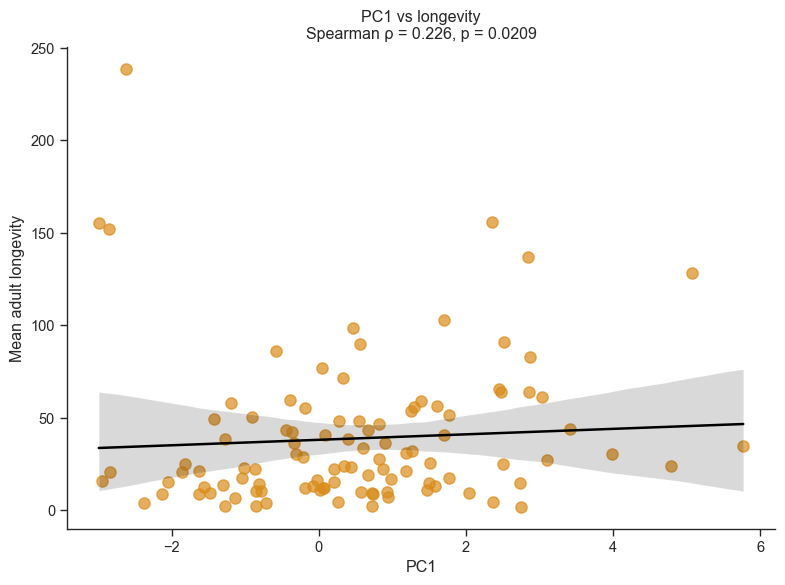

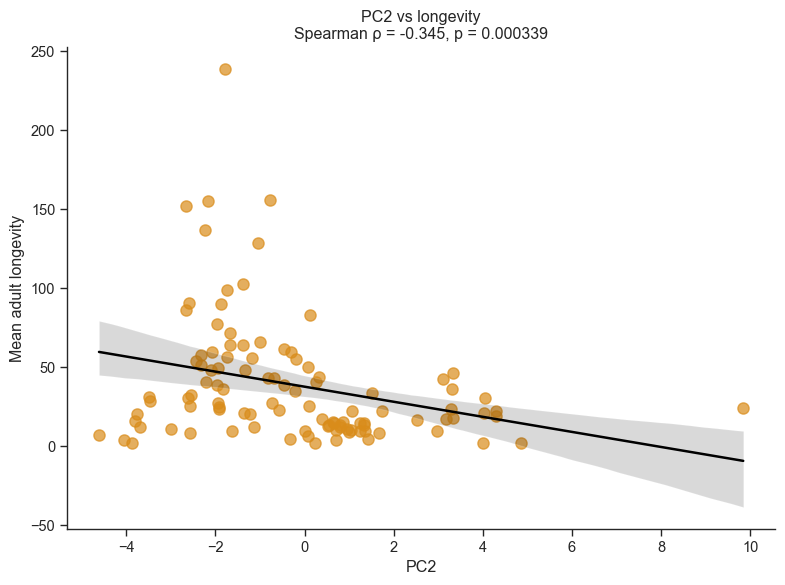

In [163]:
for component in ["PC1", "PC2"]:

    rho, p_value = spearmanr(
        family_pca[component],
        family_pca["Mean_longevity"]
    )

    fig, ax = plt.subplots(figsize=(8, 6))

    sns.regplot(
        data=family_pca,
        x=component,
        y="Mean_longevity",
        scatter_kws={
            "s": 65,
            "alpha": 0.7,
            "color": "#D98C1A"
        },
        line_kws={
            "color": "black"
        },
        ax=ax
    )

    ax.set_xlabel(component)
    ax.set_ylabel("Mean adult longevity")

    ax.set_title(
        f"{component} vs longevity\n"
        f"Spearman ρ = {rho:.3f}, p = {p_value:.3g}"
    )

    sns.despine()
    plt.tight_layout()

    plt.savefig(
        output_dir / f"COX1_{component}_longevity.pdf",
        bbox_inches="tight"
    )

    plt.show()

In [165]:
family_ratio = (
    pca_data
    .groupby("Family", as_index=False)
    .agg(
        Pro=("P_frac", "mean"),
        Phe=("F_frac", "mean"),
        Leu_TT=("Leu_TT_frac", "mean"),
        Mean_longevity=("Mean_longevity", "first"),
        N_species=("Scientific_name", "nunique")
    )
)

family_ratio["Pro_PheLeuTT_ratio"] = (
    family_ratio["Pro"] /
    (
        family_ratio["Phe"] +
        family_ratio["Leu_TT"]
    ).replace(0, np.nan)
)

family_ratio = family_ratio.dropna(
    subset=["Pro_PheLeuTT_ratio", "Mean_longevity"]
)

display(family_ratio.head())

,Family,Pro,Phe,Leu_TT,Mean_longevity,N_species,Pro_PheLeuTT_ratio
0,Acrididae,0.053037,0.070785,0.069541,89.782143,76,0.377958
1,Agromyzidae,0.053328,0.078623,0.095513,9.800000,46,0.306243
2,Aleyrodidae,0.039224,0.093093,0.115641,13.300000,11,0.187914
3,Alydidae,0.061281,0.073915,0.086135,38.450000,8,0.382889
4,Anthocoridae,0.058223,0.075242,0.074678,43.257000,10,0.388361


In [166]:
variables = [
    "Pro",
    "Phe",
    "Leu_TT",
    "Pro_PheLeuTT_ratio"
]

results = []

for var in variables:

    subset = family_ratio[
        [var, "Mean_longevity"]
    ].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    if len(subset) < 3 or subset[var].nunique() < 2:
        continue

    rho, p_value = spearmanr(
        subset[var],
        subset["Mean_longevity"]
    )

    results.append({
        "Variable": var,
        "N_families": len(subset),
        "Spearman_rho": rho,
        "p_value": p_value
    })

correlation_df = pd.DataFrame(results)

display(
    correlation_df.sort_values(
        "Spearman_rho",
        ascending=False
    ).round(4)
)

,Variable,N_families,Spearman_rho,p_value
3,Pro_PheLeuTT_ratio,104,0.1510,0.1259
1,Phe,104,0.0673,0.4971
0,Pro,104,-0.0380,0.7017
2,Leu_TT,104,-0.3245,0.0008


In [169]:
family_ratio

,Family,Pro,Phe,Leu_TT,Mean_longevity,N_species,Pro_PheLeuTT_ratio
0,Acrididae,0.053037,0.070785,0.069541,89.782143,76,0.377958
1,Agromyzidae,0.053328,0.078623,0.095513,9.800000,46,0.306243
2,Aleyrodidae,0.039224,0.093093,0.115641,13.300000,11,0.187914
3,Alydidae,0.061281,0.073915,0.086135,38.450000,8,0.382889
4,Anthocoridae,0.058223,0.075242,0.074678,43.257000,10,0.388361
...,...,...,...,...,...,...,...
99,Tingidae,0.070015,0.068493,0.080670,55.275000,3,0.469388
100,Tortricidae,0.062387,0.065393,0.105638,15.156250,264,0.364767
101,Trichogrammatidae,0.043185,0.094046,0.129248,1.800000,6,0.193401
102,Triozidae,0.063928,0.071316,0.098063,40.500000,10,0.377427


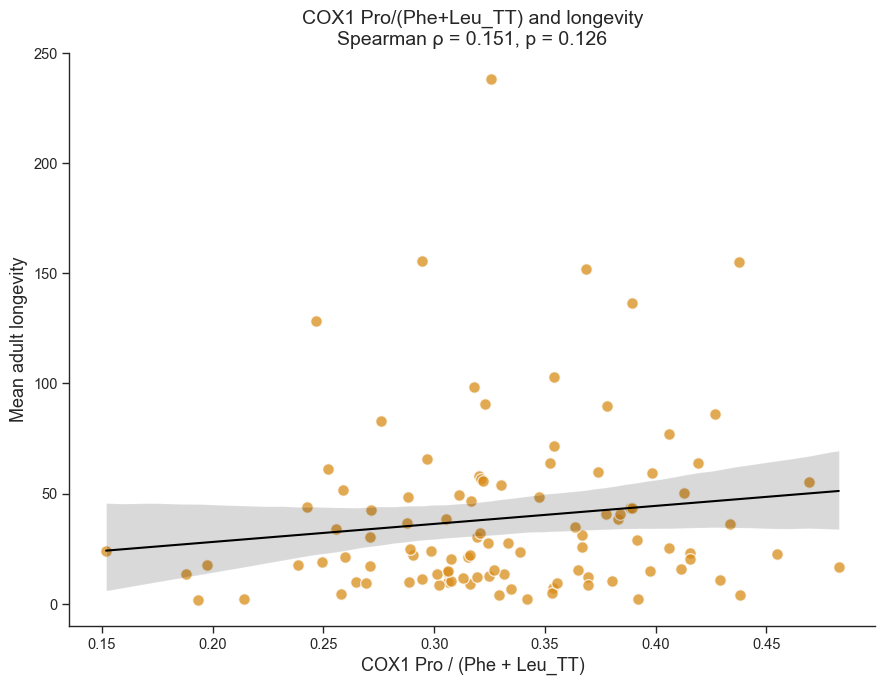

In [168]:
rho, p_value = spearmanr(
    family_ratio["Pro_PheLeuTT_ratio"],
    family_ratio["Mean_longevity"]
)

fig, ax = plt.subplots(figsize=(9, 7))

sns.regplot(
    data=family_ratio,
    x="Pro_PheLeuTT_ratio",
    y="Mean_longevity",
    scatter_kws={
        "s": 70,
        "alpha": 0.75,
        "color": "#D98C1A",
        "edgecolor": "white"
    },
    line_kws={
        "color": "black",
        "linewidth": 1.5
    },
    ax=ax
)

ax.set_xlabel(
    "COX1 Pro / (Phe + Leu_TT)",
    fontsize=13
)

ax.set_ylabel(
    "Mean adult longevity",
    fontsize=13
)

ax.set_title(
    "COX1 Pro/(Phe+Leu_TT) and longevity\n"
    f"Spearman ρ = {rho:.3f}, p = {p_value:.3g}",
    fontsize=14
)

sns.despine()
plt.tight_layout()

plt.savefig(
    output_dir / "COX1_Pro_PheLeuTT_longevity.pdf",
    bbox_inches="tight"
)

plt.show()